# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.1. Regresión lineal simple

*Bienvenidos* a este jupyter notebook que nos será de utilidad para comprender la regresión lineal.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Importación de bibliotecas

In [1]:
import warnings
warnings.filterwarnings("ignore")

#Cargar bibliotecas esenciales para el análisis de datos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 1.26.4
pandas: 3.0.6
seaborn: 0.13.2
Matplotlib: 3.11.2


#### Carga y exploración inicial de los datos

In [2]:
import pandas as pd
data = pd.read_csv("boston_housing.csv")
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [3]:
data.shape

(506, 14)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  PRICE    506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB


#### Análisis exploratorio de las relaciones con la variable de salida

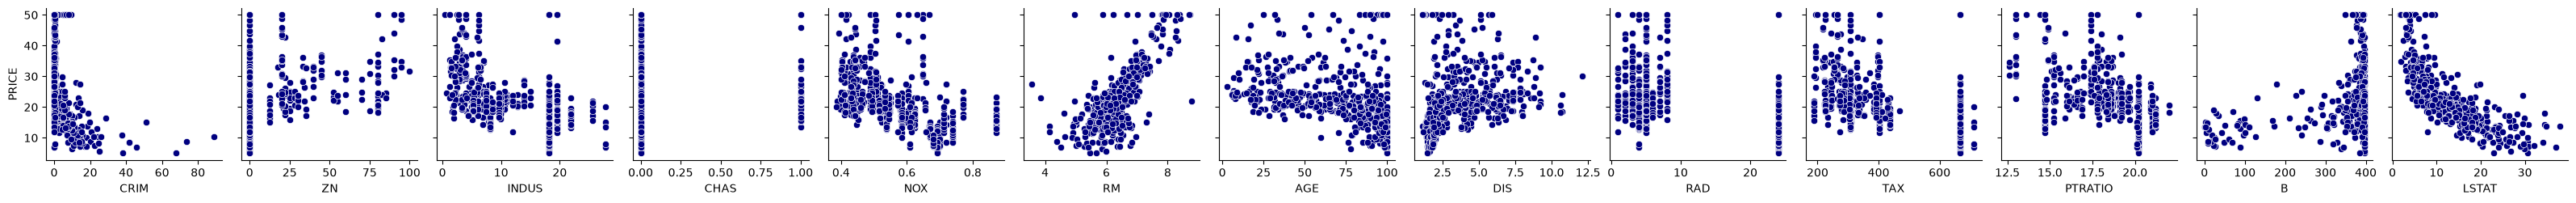

In [5]:
sns.pairplot(data=data,y_vars=['PRICE'], x_vars=['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT'], plot_kws={'color': 'navy'})

#### Relación entre el número de habitaciones y el precio

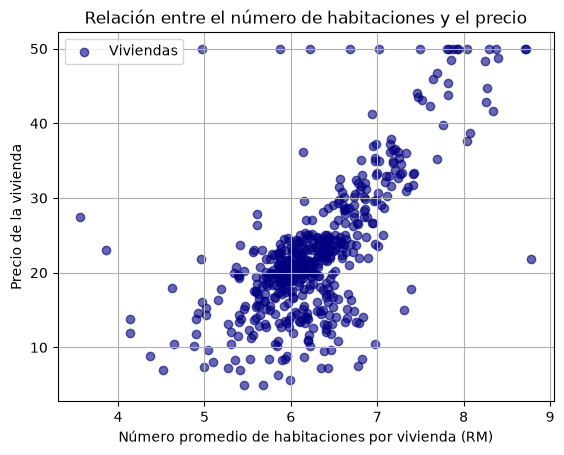

In [6]:
plt.scatter(data.RM, data.PRICE, label="Viviendas", color="navy", alpha=0.6)
plt.xlabel("Número promedio de habitaciones por vivienda (RM)")
plt.ylabel("Precio de la vivienda")
plt.title("Relación entre el número de habitaciones y el precio")
plt.legend()
plt.grid()
plt.show()

#### Construcción y ajuste del modelo de regresión lineal

In [7]:
import statsmodels.api as sm
x = data.RM
y = data.PRICE
X = sm.add_constant(x)
model = sm.OLS(y,X)
results = model.fit()

#### Visualización de la recta de regresión

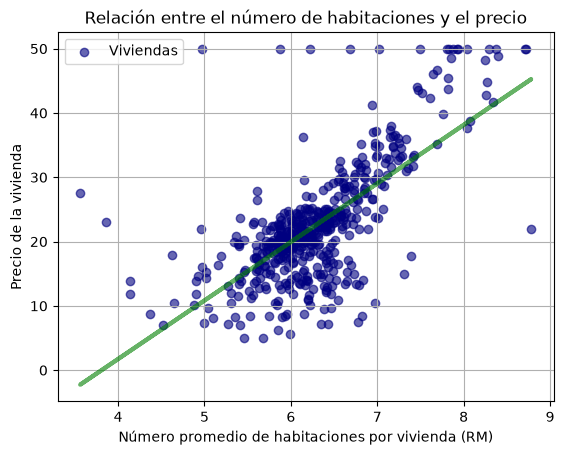

In [8]:
plt.scatter(data.RM, data.PRICE, label="Viviendas", color="navy", alpha=0.6)
plt.plot(x, results.predict(sm.add_constant(x)), c = "g", linewidth = 3, alpha = 0.6)
plt.xlabel("Número promedio de habitaciones por vivienda (RM)")
plt.ylabel("Precio de la vivienda")
plt.title("Relación entre el número de habitaciones y el precio")
plt.legend()
plt.grid()
plt.show()

#### Interpretación de los coeficientes y del coeficiente de determinación

In [9]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  PRICE   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     471.8
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           2.49e-74
Time:                        00:24:24   Log-Likelihood:                -1673.1
No. Observations:                 506   AIC:                             3350.
Df Residuals:                     504   BIC:                             3359.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -34.6706      2.650    -13.084      0.000     -39.877     -29.465
RM             9.1021      0.419     21.722      0.000       8.279       9.925
==============================================================================
Omnibus:                      102.585   Durbin-Watson:                   0.684
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              612.449
Skew:                           0.726   Prob(JB):                    1.02e-133
Kurtosis:                       8.190   Cond. No.                         58.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Evaluación del error: RMSE y RSE

In [10]:
residuos = results.resid

rmse = np.sqrt(np.mean(residuos**2))
rse = np.sqrt(results.ssr / results.df_resid)

print(f"RMSE: {rmse:.4f}")
print(f"RSE: {rse:.4f}")

RMSE: 6.6031
RSE: 6.6162


#### Análisis de residuos

##### Residuos frente a valores ajustados

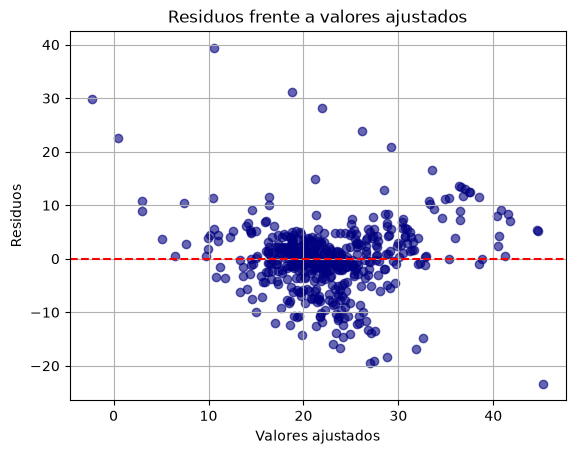

In [11]:
plt.scatter(
    results.fittedvalues,
    results.resid,
    color="navy",
    alpha=0.6
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos frente a valores ajustados")
plt.grid()
plt.show()

##### Distribución de los residuos

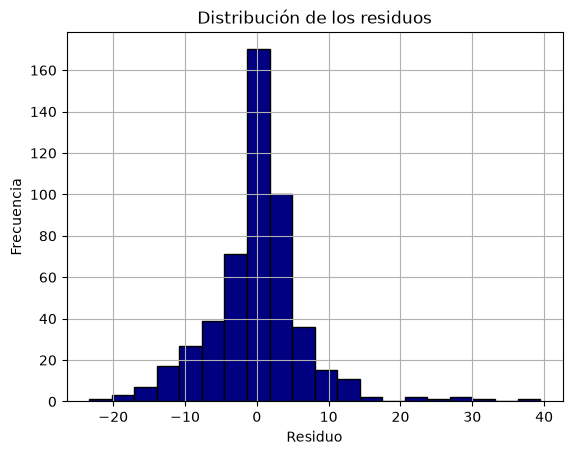

In [12]:
# Análisis de residuos
residuos = results.resid

# Histograma
plt.hist(residuos, bins=20, color="navy", edgecolor='black')
plt.title('Distribución de los residuos')
plt.xlabel('Residuo')
plt.ylabel('Frecuencia')
plt.grid()
plt.show()

##### Evaluación visual de la normalidad: gráfico Q-Q

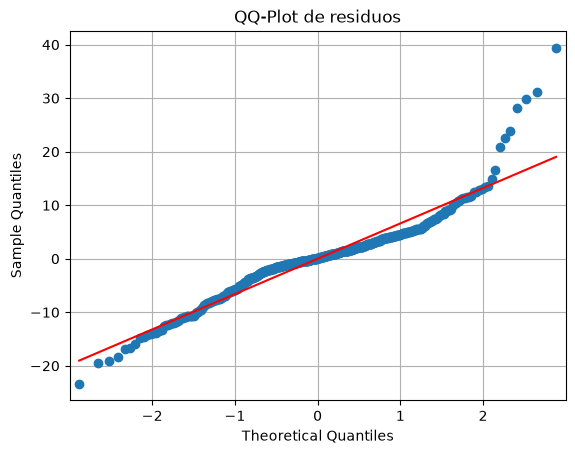

In [13]:
# QQ-plot
sm.qqplot(residuos, line='s')
plt.title("QQ-Plot de residuos")
plt.grid()
plt.show()

#### Significancia estadística de los coeficientes

In [14]:
results.pvalues

const    6.950229e-34
RM       2.487229e-74
dtype: float64

#### Visualizaciones complementarias con regplot y jointplot

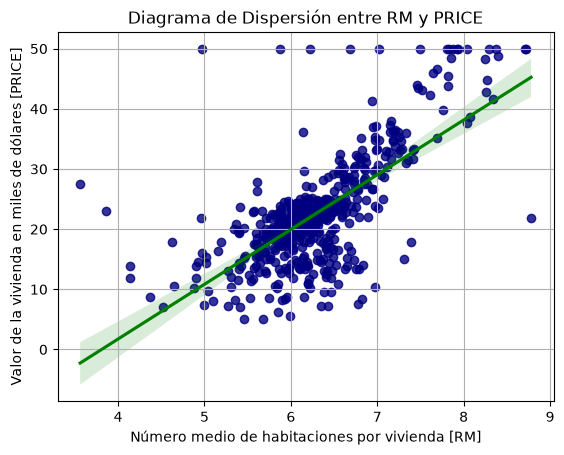

In [15]:
sns.regplot(y="PRICE", x="RM", data=data, fit_reg = True, scatter_kws={"color": "navy"}, line_kws={"color": "green"})
plt.xlabel("Número medio de habitaciones por vivienda [RM]")
plt.ylabel("Valor de la vivienda en miles de dólares [PRICE]")
plt.title("Diagrama de Dispersión entre RM y PRICE")
plt.grid()
plt.show()

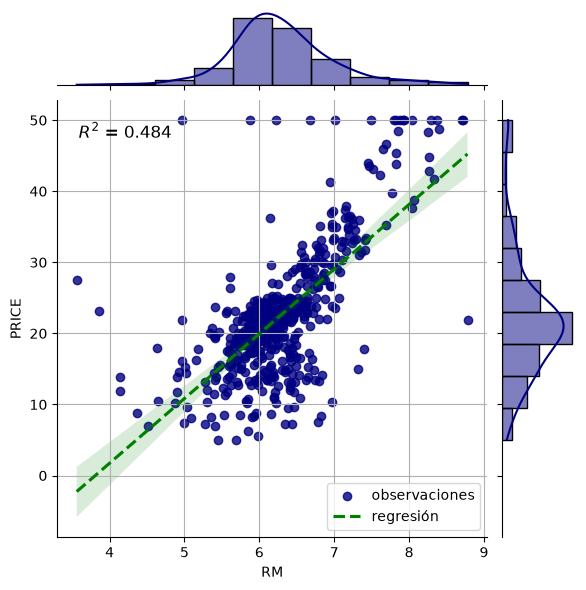

In [16]:
r2 = results.rsquared


# Crear jointplot con bins más pequeños
g = sns.jointplot(data=data,
    x=data.RM,
    y=data.PRICE,
    kind="reg",
    marginal_kws=dict(bins=10, fill=True, color="navy", edgecolor="black"),
    line_kws={'color':'green','linestyle': '--','label':'regresión'},
    scatter_kws={'color':'navy'},
    label= 'observaciones'
)

# Añadir texto con R²
g.ax_joint.text(
    0.05, 0.95, f"$R^2$ = {r2:.3f}",
    transform=g.ax_joint.transAxes,
    fontsize=12, verticalalignment="top"
)

# Agregar cuadrícula
g.ax_joint.grid(True)
plt.legend()
plt.show()